# Step 4b: FP16 vs quantized KV cache on a small model (one notebook, FP16 baseline included)

**Why.** Qwen3-4B was at 100% with an FP16 cache at every length the T4 can reach (2K to 16K), so FP8 vs FP16 could not be separated: the test had no room to show a loss. A 0.5B model is weaker at retrieval, so its FP16 baseline should fall below 100% somewhere in the range, and an FP8 loss (if any) has room to appear.

**What runs.** For one model (`MODEL` below): FP16 cache, then FP8 e4m3, then FP8 e5m2, on the same grid of prompts (same builder, same seed, so trials are paired within the model). Lengths go up to 32K, which these small models support natively and which fits on a T4 (KV cache at 32K: about 0.4 GiB for the GQA model, about 3 GiB for the MHA model). Run the notebook once per model: `Qwen/Qwen2.5-0.5B-Instruct` (GQA) and `Qwen/Qwen1.5-0.5B-Chat` (MHA); this is also the model pair for the MHA vs GQA part of the project. Results files are named per model, so the two runs do not overwrite each other.

**What is simulated.** As in the earlier FP8 notebook: K and V are rounded to the target format when written to the cache and stay in FP16 memory; prefill attention is exact (`PREFILL_EXACT`), decode reads quantized values. Memory saving comes from the formula, not from this run.

**How to read it.** The useful outcome is a heatmap where FP16 is below 100% at long lengths, plus the paired table FP16 vs FP8. If FP16 is still 100% everywhere for the small model too, say so; if FP16 is already near 0% at the long lengths, those cells carry no information, so compare only where FP16 is between about 30% and 95%.

**Order:** setup, config, model, haystack, prompt builder, generation, quantizers, cache, smoke test, run all modes, paired comparison, download.

In [20]:
%pip install -q -U transformers accelerate datasets matplotlib pandas tqdm

In [21]:
import json, os, random, re, time, math
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Switch the runtime to a GPU"
GPU_NAME = torch.cuda.get_device_name(0)
print(torch.__version__, GPU_NAME, f"{torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GiB")

# Results live on Google Drive: they survive runtime resets and are shared with the FP8 notebook
# (every notebook gets its own Colab runtime, and /content is not shared between runtimes).
from google.colab import drive
drive.mount("/content/drive")
RESULTS_DIR = "/content/drive/MyDrive/kv-cache/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

2.14.1+cu130 Tesla T4 14.6 GiB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Config
`ESCALATION` is tried in order. The first mode runs the full grid; the later ones run only at 16K (where degradation is most likely) to save time. The loop stops at the first mode that is below 100%.

In [22]:
MODEL = "Qwen/Qwen2.5-0.5B-Instruct"     # GQA run. For the MHA run use "Qwen/Qwen1.5-0.5B-Chat"
SHORT = MODEL.split("/")[-1]

CFG = dict(
    model_id=MODEL,
    lengths=[2048, 4096, 8192, 16384, 32768],
    depths=[0, 25, 50, 75, 100],
    n_variants=5,
    max_new_tokens=24,
    seed=0,
    tag="fp16",
)
MODES = ["fp16", "fp8_e4m3", "fp8_e5m2"]        # add "int4" at the end if you want a deliberately lossy reference
PREFILL_EXACT = True
SMOKE_PATH = f"{RESULTS_DIR}/needle_{SHORT}_smoke.jsonl"
SMOKE = dict(lengths=[2048], depths=[0, 50, 100], n_variants=2)
def rpath(mode): return f"{RESULTS_DIR}/needle_{SHORT}_{mode}.jsonl"

## Model

In [23]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(CFG["model_id"])
model = AutoModelForCausalLM.from_pretrained(
    CFG["model_id"], torch_dtype=torch.float16, device_map="cuda", attn_implementation="sdpa"
).eval()

mc = model.config
head_dim = getattr(mc, "head_dim", mc.hidden_size // mc.num_attention_heads)
KV_BYTES_PER_TOKEN = 2 * mc.num_hidden_layers * mc.num_key_value_heads * head_dim * 2   # FP16
weights_gib = sum(p.numel() * p.element_size() for p in model.parameters()) / 2**30
print(f"layers {mc.num_hidden_layers}, q heads {mc.num_attention_heads}, kv heads {mc.num_key_value_heads}, head_dim {head_dim}")
print(f"weights {weights_gib:.2f} GiB, KV cache {KV_BYTES_PER_TOKEN/1024:.0f} KiB/token "
      f"-> {KV_BYTES_PER_TOKEN*16384/2**30:.2f} GiB at 16K")

# sanity check
msgs = [{"role": "user", "content": "Say hello in five words."}]
ids = tok.apply_chat_template(msgs, add_generation_prompt=True, enable_thinking=False,
                              return_tensors="pt", return_dict=True).to("cuda")
out = model.generate(**ids, max_new_tokens=16, do_sample=False, temperature=None, top_p=None, top_k=None)
print(repr(tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

layers 24, q heads 14, kv heads 2, head_dim 64
weights 0.92 GiB, KV cache 12 KiB/token -> 0.19 GiB at 16K
'Hello! How can I assist you today?'


## Haystack

In [24]:
from datasets import load_dataset

ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
raw = " ".join(t.strip() for t in ds["text"] if t.strip() and not t.strip().startswith("="))
raw = raw.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
SENTS = [s for s in re.split(r"(?<=[.!?])\s+", raw) if 40 <= len(s) <= 400][:40000]
SENT_TOK = [len(x) for x in tok(SENTS, add_special_tokens=False)["input_ids"]]
print(len(SENTS), "sentences,", sum(SENT_TOK), "tokens, mean", round(np.mean(SENT_TOK), 1), "tokens/sentence")

40000 sentences, 1263383 tokens, mean 31.6 tokens/sentence


## Needles and prompt builder
Copied unchanged from the FP16 notebook so the prompts are identical.

In [25]:
PLACES = ["Marlowe Harbor", "Quillfeather", "Brindlemoor", "Tessaly Ridge",
          "Orrin Falls", "Valdemar Bay", "Pellam Crossing", "Ashgrove Mill"]

def ntok(s):
    return len(tok(s, add_special_tokens=False)["input_ids"])

def build_prompt(target_len, depth, variant, seed=CFG["seed"], overhead=60):
    place = PLACES[variant % len(PLACES)]
    value = str(random.Random(f"val-{seed}-{variant}").randint(100000, 999999))
    needle = f"The special magic number for {place} is {value}."
    question = f"What is the special magic number for {place}?"
    budget = target_len - overhead - ntok(needle) - ntok(question)

    rng = random.Random(f"hay-{seed}-{target_len}-{variant}")       # same haystack at every depth
    start = rng.randrange(0, len(SENTS) - 2000)
    chosen, total, i = [], 0, start
    while total < budget:
        chosen.append(SENTS[i]); total += SENT_TOK[i]; i += 1

    k = round(depth / 100 * len(chosen))                             # needle goes before sentence k
    actual_depth = 100 * sum(SENT_TOK[start:start + k]) / total
    text = " ".join(chosen[:k] + [needle] + chosen[k:])
    prompt = f"{text}\n\nBased only on the text above, {question} Reply with just the number."
    return prompt, dict(value=value, actual_depth=actual_depth, place=place)

# check: the value appears exactly once (in the needle), length and depth are close to the targets
p, m = build_prompt(2048, 50, 0)
assert p.count(m["value"]) == 1
print("tokens in prompt text:", ntok(p), "| actual depth:", round(m["actual_depth"], 1), "%")

tokens in prompt text: 2006 | actual depth: 56.2 %


## Generation
Same as before, except the cache argument is named `cache` in transformers 5.x and `past_key_values` in 4.x.

In [26]:
import transformers
CACHE_KW = "cache" if int(transformers.__version__.split(".")[0]) >= 5 else "past_key_values"

@torch.no_grad()
def answer(prompt, max_new_tokens, cache=None):
    msgs = [{"role": "user", "content": prompt}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    ids = tok(text, return_tensors="pt", add_special_tokens=False).input_ids.to("cuda")
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    kw = {CACHE_KW: cache} if cache is not None else {}
    out = model.generate(ids, max_new_tokens=max_new_tokens, do_sample=False,
                         temperature=None, top_p=None, top_k=None, **kw)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    peak = torch.cuda.max_memory_allocated()
    return tok.decode(out[0][ids.shape[1]:], skip_special_tokens=True), ids.shape[1], dt, peak

## Trial and grid runner
Same as before: one JSON line per trial, resumes after a disconnect, marks OOM lengths.

In [27]:
def run_trial(L, d, v, make_cache=None):
    prompt, meta = build_prompt(L, d, v)
    cache = make_cache() if make_cache is not None else None
    out_text, n_in, dt, peak = answer(prompt, CFG["max_new_tokens"], cache)
    correct = meta["value"] in out_text.replace(",", "").replace(" ", "")
    return dict(tag=CFG["tag"], length=L, depth=d, variant=v, n_tokens=n_in,
                actual_depth=round(meta["actual_depth"], 1), expected=meta["value"],
                output=out_text.strip(), correct=bool(correct),
                seconds=round(dt, 2), peak_gib=round(peak / 2**30, 2), status="ok")

def run_grid(lengths, depths, n_variants, path, make_cache=None, retry_oom=False):
    done = set()
    if os.path.exists(path):
        for line in open(path):
            r = json.loads(line)
            if r["status"] == "ok" or not retry_oom:
                done.add((r["length"], r["depth"], r["variant"]))
    todo = [(L, d, v) for L in lengths for d in depths for v in range(n_variants) if (L, d, v) not in done]
    oom_at = []
    with open(path, "a") as f:
        for L, d, v in tqdm(todo):
            if any(L >= x for x in oom_at):
                rec = dict(tag=CFG["tag"], length=L, depth=d, variant=v, status="oom")
            else:
                try:
                    rec = run_trial(L, d, v, make_cache)
                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache(); oom_at.append(L)
                    print(f"OOM at length {L}; marking this and longer lengths as oom")
                    rec = dict(tag=CFG["tag"], length=L, depth=d, variant=v, status="oom")
            f.write(json.dumps(rec) + "\n"); f.flush()
    return pd.read_json(path, lines=True)

## Quantizers
- **FP8 e4m3 / e5m2:** round-trip through the 8-bit float format (values clamped to the format's range). e4m3 has 3 mantissa bits (relative error up to about 6%), e5m2 has 2 (about 12%), with a larger range. If the GPU or PyTorch build cannot cast to float8, an exact emulation is used instead. The first cell below checks that the native cast and the emulation agree.
- **INT8 / INT4:** asymmetric min-max quantization per token and per head (over `head_dim`). This is a simple baseline; methods like KIVI quantize keys per channel because keys have outlier channels, so per-token INT4 on keys is expected to be harmful.

In [28]:
FP8_FMT = {"fp8_e4m3": dict(dtype="float8_e4m3fn", mb=3, emin=-6, vmax=448.0),
           "fp8_e5m2": dict(dtype="float8_e5m2",   mb=2, emin=-14, vmax=57344.0)}

def fp8_native(x, fmt):
    c = FP8_FMT[fmt]
    return x.float().clamp(-c["vmax"], c["vmax"]).to(getattr(torch, c["dtype"])).to(x.dtype)

def fp8_emulated(x, fmt):
    c = FP8_FMT[fmt]
    xf = x.float().clamp(-c["vmax"], c["vmax"])
    e = torch.floor(torch.log2(xf.abs().clamp(min=2.0 ** (c["emin"] - c["mb"]))))
    e = e.clamp(min=c["emin"])
    step = 2.0 ** (e - c["mb"])
    return (torch.round(xf / step) * step).clamp(-c["vmax"], c["vmax"]).to(x.dtype)

def quant_int(x, bits):
    xf = x.float()
    mn, mx = xf.amin(-1, keepdim=True), xf.amax(-1, keepdim=True)
    qmax = 2 ** bits - 1
    scale = ((mx - mn) / qmax).clamp(min=1e-8)
    return (torch.round((xf - mn) / scale).clamp(0, qmax) * scale + mn).to(x.dtype)

# choose native or emulated FP8 for this GPU
probe = torch.cat([torch.randn(1 << 15), torch.randn(1 << 15) * 1e-3, torch.randn(1 << 15) * 100]).half().cuda()
IMPL = {}
for fmt in FP8_FMT:
    emu = fp8_emulated(probe, fmt)
    try:
        nat = fp8_native(probe, fmt)
        IMPL[fmt] = fp8_native
        print(f"{fmt}: native cast works; differs from emulation in {int((nat != emu).sum())} of {probe.numel()} values")
    except Exception as e:
        IMPL[fmt] = fp8_emulated
        print(f"{fmt}: native cast failed ({type(e).__name__}); using emulation")

def get_qfn(mode):
    if mode in FP8_FMT:
        f = IMPL[mode]; return lambda x: f(x, mode)
    if mode == "int8": return lambda x: quant_int(x, 8)
    if mode == "int4": return lambda x: quant_int(x, 4)
    raise ValueError(mode)

# relative error on random data, as a rough scale of how lossy each mode is
x = torch.randn(1, 8, 512, 128, device="cuda").half()
for mode in ["fp8_e4m3", "fp8_e5m2", "int8", "int4"]:
    q = get_qfn(mode)(x)
    print(f"{mode:9s} relative error {((q.float() - x.float()).norm() / x.float().norm()).item():.4f}")

fp8_e4m3: native cast works; differs from emulation in 0 of 98304 values
fp8_e5m2: native cast works; differs from emulation in 0 of 98304 values
fp8_e4m3  relative error 0.0266
fp8_e5m2  relative error 0.0529
int8      relative error 0.0059
int4      relative error 0.0997


## Quantizing cache
Subclass of `DynamicCache`: every K/V written to the cache goes through the quantizer. With `PREFILL_EXACT`, the first write of each layer (the prompt) returns the exact states for the attention of that forward pass but stores the quantized ones, so every later decode step reads quantized values. The sanity cell prints the real K/V relative error for each mode on an actual prompt.

In [29]:
from transformers import DynamicCache

class QuantCache(DynamicCache):
    def __init__(self, qfn, prefill_exact=True, record=False):
        try:
            super().__init__(config=model.config)
        except TypeError:
            super().__init__()
        self.qfn, self.prefill_exact = qfn, prefill_exact
        self.stats = [] if record else None

    def update(self, key_states, value_states, layer_idx, *args, **kwargs):
        first = self.get_seq_length(layer_idx) == 0
        qk, qv = self.qfn(key_states), self.qfn(value_states)
        if self.stats is not None:
            kf, vf = key_states.float(), value_states.float()
            self.stats.append((((qk.float() - kf).norm() / kf.norm()).item(),
                               ((qv.float() - vf).norm() / vf.norm()).item()))
        k, v = super().update(qk, qv, layer_idx, *args, **kwargs)
        if first and self.prefill_exact:
            return key_states, value_states
        return k, v

def qcache(mode, record=False):
    return lambda: QuantCache(get_qfn(mode), PREFILL_EXACT, record)

# sanity: run one real prompt per mode and print the K/V error actually seen
prompt, meta = build_prompt(1024, 50, 0)
for mode in ["fp8_e4m3", "fp8_e5m2", "int8", "int4"]:
    c = qcache(mode, record=True)()
    out, n_in, dt, peak = answer(prompt, 8, c)
    s = np.array(c.stats)
    print(f"{mode:9s} K rel. error {s[:, 0].mean():.4f}, V rel. error {s[:, 1].mean():.4f} | answer: {out.strip()!r} (expected {meta['value']})")

fp8_e4m3  K rel. error 0.0263, V rel. error 0.0265 | answer: '532191' (expected 532191)
fp8_e5m2  K rel. error 0.0533, V rel. error 0.0531 | answer: '532191' (expected 532191)
int8      K rel. error 0.0070, V rel. error 0.0063 | answer: '532191' (expected 532191)
int4      K rel. error 0.1181, V rel. error 0.1067 | answer: '5321911' (expected 532191)


## Smoke test
Six trials with FP8 e4m3. Check that answers look right and that the time per trial is reasonable.

In [30]:
CFG["tag"] = "fp8_e4m3"
sm = run_grid(SMOKE["lengths"], SMOKE["depths"], SMOKE["n_variants"], SMOKE_PATH, make_cache=qcache("fp8_e4m3"))
print(sm[["length", "n_tokens", "depth", "variant", "expected", "output", "correct", "seconds", "peak_gib"]].to_string())

0it [00:00, ?it/s]

   length  n_tokens  depth  variant  expected  output  correct  seconds  peak_gib
0    2048      2035      0        0    532191  532191     True     0.66      1.04
1    2048      2049      0        1    940005  940005     True     0.33      1.04
2    2048      2035     50        0    532191  532191     True     0.29      1.04
3    2048      2049     50        1    940005  940005     True     0.29      1.04
4    2048      2035    100        0    532191  532191     True     0.30      1.04
5    2048      2049    100        1    940005  940005     True     0.29      1.04


## Run all modes
FP16 first, then each quantized mode, all on the full grid (125 trials per mode). Results go to `needle_<model>_<mode>.jsonl` on Drive; rerunning resumes. An OOM at some length is recorded and longer lengths are skipped. If the session disconnects, rerun the cell.

In [31]:
def run_mode(mode):
    CFG["tag"] = mode
    mk = None if mode == "fp16" else qcache(mode)
    return run_grid(CFG["lengths"], CFG["depths"], CFG["n_variants"], rpath(mode), make_cache=mk)

def save_to_drive():
    # Colab syncs Drive writes lazily; unmount forces the sync, then remount so the next mode can write
    drive.flush_and_unmount()
    drive.mount("/content/drive", force_remount=True)

# for mode in MODES:
#     d = run_mode(mode)
#     ok = d[d.status == "ok"]
#     per_len = ok.groupby("length").correct.mean().round(2).to_dict()
#     print(f"{mode}: {int(ok.correct.sum())}/{len(ok)} correct, {int((d.status == 'oom').sum())} oom | by length {per_len}")
#     save_to_drive()
#     print(f"saved {rpath(mode)}")

## Results and paired comparison
For each mode: the heatmap, and a per-length table with the FP16 and quantized success counts on the *same* trials. `fp16_only` = FP16 right and quantized wrong; `quant_only` = the reverse. Wrong answers are listed so you can see whether they are garbled or just a different number.

In [32]:
def summarize(df):
    ok = df[df.status == "ok"]
    return ok.groupby(["length", "depth"])["correct"].agg(k="sum", n="size").reset_index()

def plot_heatmap(df, title, fname):
    g = summarize(df)
    lengths, depths = sorted(g.length.unique()), sorted(g.depth.unique())
    M = np.full((len(depths), len(lengths)), np.nan)
    for r in g.itertuples():
        M[depths.index(r.depth), lengths.index(r.length)] = r.k / r.n
    fig, ax = plt.subplots(figsize=(1.5 * len(lengths) + 2, 0.7 * len(depths) + 1.8))
    im = ax.imshow(M, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(lengths))); ax.set_xticklabels([f"{L//1024}K" for L in lengths])
    ax.set_yticks(range(len(depths)));  ax.set_yticklabels([f"{d}%" for d in depths])
    ax.set_xlabel("context length (tokens)"); ax.set_ylabel("needle depth")
    for r in g.itertuples():
        ax.text(lengths.index(r.length), depths.index(r.depth), f"{int(r.k)}/{int(r.n)}",
                ha="center", va="center", fontsize=9)
    fig.colorbar(im, ax=ax, label="success rate")
    ax.set_title(title, fontsize=10)
    fig.savefig(fname, dpi=160, bbox_inches="tight"); plt.show()

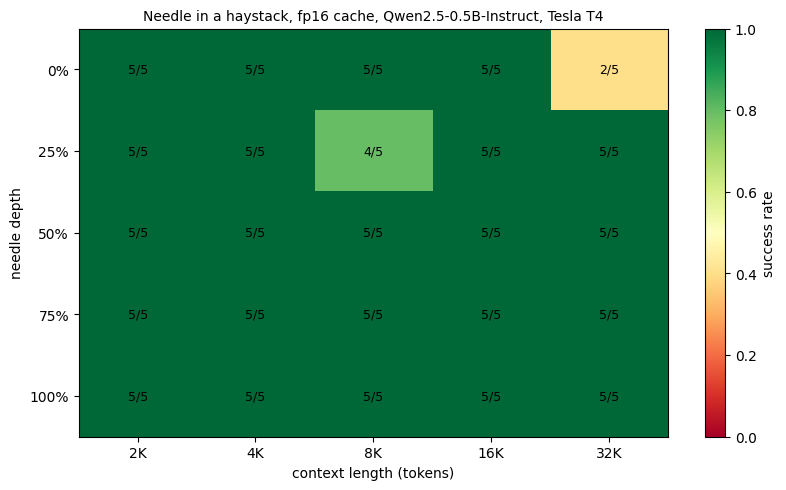

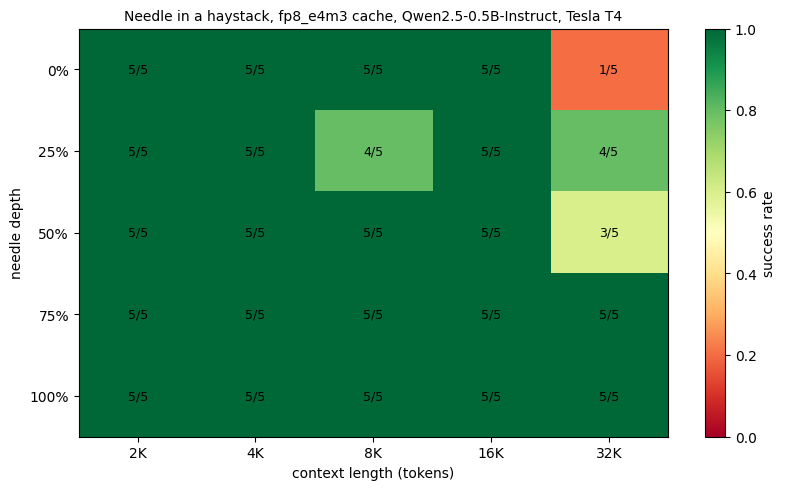

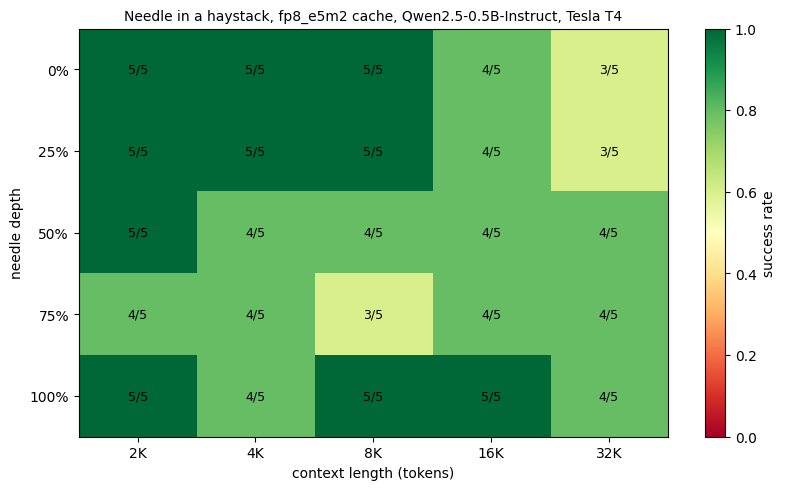


    mode  length  n  fp16  quant  fp16_only  quant_only
fp8_e4m3    2048 25    25     25          0           0
fp8_e4m3    4096 25    25     25          0           0
fp8_e4m3    8192 25    24     24          0           0
fp8_e4m3   16384 25    25     25          0           0
fp8_e4m3   32768 25    22     18          5           1
fp8_e5m2    2048 25    25     24          1           0
fp8_e5m2    4096 25    25     22          3           0
fp8_e5m2    8192 25    24     22          3           1
fp8_e5m2   16384 25    25     21          4           0
fp8_e5m2   32768 25    22     18          5           1


In [33]:
results = {m: pd.read_json(rpath(m), lines=True) for m in MODES if os.path.exists(rpath(m))}
assert "fp16" in results, "FP16 results missing"
f16 = results["fp16"]
f16 = f16[f16.status == "ok"][["length", "depth", "variant", "correct"]].rename(columns={"correct": "fp16"})

rows = []
for mode, d in results.items():
    plot_heatmap(d, f"Needle in a haystack, {mode} cache, {SHORT}, {GPU_NAME}", f"{RESULTS_DIR}/needle_{SHORT}_{mode}_heatmap.png")
    if mode == "fp16":
        continue
    q = d[d.status == "ok"].rename(columns={"correct": "quant"})
    m = q.merge(f16, on=["length", "depth", "variant"], how="inner")
    for L, g in m.groupby("length"):
        rows.append(dict(mode=mode, length=L, n=len(g), fp16=int(g.fp16.sum()), quant=int(g.quant.sum()),
                         fp16_only=int((g.fp16 & ~g.quant).sum()), quant_only=int((~g.fp16 & g.quant).sum())))
print()
print(pd.DataFrame(rows).to_string(index=False))

## Download
Results are already on Drive. This also downloads a zip and flushes pending Drive writes.

In [34]:
save_to_drive()
for f in sorted(os.listdir(RESULTS_DIR)):
    if f.startswith(f"needle_{SHORT}"):
        print(f"{f:60s} {os.path.getsize(os.path.join(RESULTS_DIR, f)) / 1024:8.1f} KiB")

Mounted at /content/drive
needle_Qwen2.5-0.5B-Instruct_fp16.jsonl                          25.6 KiB
needle_Qwen2.5-0.5B-Instruct_fp16_heatmap.png                    53.9 KiB
needle_Qwen2.5-0.5B-Instruct_fp8_e4m3.jsonl                      26.1 KiB
needle_Qwen2.5-0.5B-Instruct_fp8_e4m3_heatmap.png                54.4 KiB
needle_Qwen2.5-0.5B-Instruct_fp8_e5m2.jsonl                      26.1 KiB
needle_Qwen2.5-0.5B-Instruct_fp8_e5m2_heatmap.png                58.0 KiB
needle_Qwen2.5-0.5B-Instruct_smoke.jsonl                          1.2 KiB


## Error Pattern

In [35]:
import re, math
from collections import Counter

def mcnemar_p(b, c):
    # exact two-sided test on discordant pairs (b = fp16 right / quant wrong, c = reverse)
    n = b + c
    if n == 0: return 1.0
    return min(1.0, 2 * sum(math.comb(n, k) for k in range(min(b, c) + 1)) / 2 ** n)

def err_type(expected, output):
    nums = re.findall(r"\d+", output.replace(",", ""))
    if not nums: return "no number"
    six = [x for x in nums if len(x) == 6]
    if not six: return f"other digits ({nums[0]})"
    diff = sum(a != b for a, b in zip(six[0], expected))
    return "near miss (1-2 digits off)" if diff <= 2 else "different 6-digit number"

R = {m: pd.read_json(rpath(m), lines=True) for m in MODES if os.path.exists(rpath(m))}
base = R["fp16"].query("status == 'ok'")[["length", "depth", "variant", "correct"]].rename(columns={"correct": "fp16"})

# 1. paired counts and significance, per length and total
rows = []
for m in [x for x in R if x != "fp16"]:
    q = R[m].query("status == 'ok'")[["length", "depth", "variant", "correct"]].rename(columns={"correct": "q"})
    j = q.merge(base, on=["length", "depth", "variant"])
    for L, g in list(j.groupby("length")) + [("all", j)]:
        b, c = int((g.fp16 & ~g.q).sum()), int((~g.fp16 & g.q).sum())
        rows.append(dict(mode=m, length=L, n=len(g), fp16=int(g.fp16.sum()), quant=int(g.q.sum()),
                         fp16_only=b, quant_only=c, p=round(mcnemar_p(b, c), 3)))
print(pd.DataFrame(rows).to_string(index=False))

# 2. every wrong answer, all modes, with its error type
wrong = []
for m, d in R.items():
    w = d.query("status == 'ok' and not correct").copy()
    w["mode"] = m
    w["type"] = [err_type(e, o) for e, o in zip(w.expected.astype(str), w.output.astype(str))]
    wrong.append(w)
W = pd.concat(wrong)
print("\nerror types per mode")
print(pd.crosstab(W["mode"], W["type"]).to_string())
print("\nwrong answers")
print(W.sort_values(["length", "depth", "variant", "mode"])[["mode", "length", "depth", "actual_depth", "variant", "expected", "output", "type"]].to_string(index=False))

# 3. are failures the same prompts across modes (hard prompts) or mode-specific?
key = W.groupby(["length", "depth", "variant"])["mode"].apply(lambda s: "+".join(sorted(s)))
print("\nwhich modes fail on the same prompt")
print(Counter(key).most_common())

    mode length   n  fp16  quant  fp16_only  quant_only     p
fp8_e4m3   2048  25    25     25          0           0 1.000
fp8_e4m3   4096  25    25     25          0           0 1.000
fp8_e4m3   8192  25    24     24          0           0 1.000
fp8_e4m3  16384  25    25     25          0           0 1.000
fp8_e4m3  32768  25    22     18          5           1 0.219
fp8_e4m3    all 125   121    117          5           1 0.219
fp8_e5m2   2048  25    25     24          1           0 1.000
fp8_e5m2   4096  25    25     22          3           0 0.250
fp8_e5m2   8192  25    24     22          3           1 0.625
fp8_e5m2  16384  25    25     21          4           0 0.125
fp8_e5m2  32768  25    22     18          5           1 0.219
fp8_e5m2    all 125   121    107         16           2 0.001

error types per mode
type      other digits (3)  other digits (38971)  other digits (5)  other digits (53219)  other digits (86)  other digits (86408)  other digits (86800)  other digits (86884

In [ ]:
import json, time
from google.colab import _message

nb_json = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
stamp = time.strftime("%Y%m%d_%H%M")
nb_path = f"{RESULTS_DIR}/needle_{SHORT}_run_{stamp}.ipynb"
with open(nb_path, "w") as f:
    json.dump(nb_json, f)
save_to_drive()
n_out = sum(len(c.get("outputs", [])) for c in nb_json["cells"] if c["cell_type"] == "code")
print(f"saved {nb_path}: {len(nb_json['cells'])} cells, {n_out} outputs, {os.path.getsize(nb_path) / 1024:.0f} KiB")

## For the report
- State what was simulated (K and V rounded at write time, stored in FP16, prefill exact) and that memory saving is from the formula.
- Report the FP16 baseline of each small model by length first: it shows where the test has room. Differences between FP16 and FP8 only mean something in cells where FP16 is below 100%.
- 5 trials per cell is small: use the per-length totals (25 trials) and the paired columns `fp16_only` / `quant_only`, not single cells. If the two columns are about equal and small, the difference is noise.
- The scope of the claim is these two 0.5B models and single-needle retrieval up to 32K on a T4; Qwen3-4B was saturated (100%) up to 16K.